# 2. házi feladat

A második házi feladatban egy egyszerű képi objektum-detektort készítünk, amivel megtanuljuk megoldani a "Hová tűnt Vili?" ("Where's Waldo?") rejtvényeket. Ennek keretében, nagy méretű képeken kell megtalálni a főhőst, Vilit. Az objektum-detektort egy bináris kép-klasszifikációra ("van Vili" / "nincs Vili"), képrészleteken betanított konvolúciós háló segítségével valósítjuk meg. A háló betanítását követően, a nagyméretű Vili képrejtvényeinket, felosztjuk kisebb négyzetekre, majd az így kapott képrészletek klasszifikációjával próbáljuk meg megtalálni a képeken Vilit.

Sajnos kevés ilyen képrejtvény áll rendelkezésünkre, így néhány kézzel rajzolt, kivágott Vili-fejből és véletlen hátterekből összerakott szintetikus példák segítségével tanítjuk be a klasszifikációs hálónkat. Ezeket a szintetikus példákat két függvény generálja majd: az egyik Vili-ket tartalmazó (pozitív) képeket, a másik Vili nélküli (negatív) képeket generál. A neuronhálónk alapját egy, az ImageNet adatbázison előtanított mély konvolúciós háló (MobileNet v2) adja.

A házi feladat több részfeladatból áll (A - J), melyek egymásra épülnek. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, a tesztelő által lefuttatott tesztek sikeresek voltak. Azonban, a tesztelőszkript nem képes a megoldás helyességét minden szempont szerint ellenőrizni. A kód ellenőrzésére szolgálnak a vizualizációs feldatok is, ahol a kirajzolt képek szemrevételezésével is kiszűrhetők hibák. Mindezek ellenére, nem minden fajta hibát könnyű észrevenni a kódban, így elképzelhető, hogy beadás után további javításokat kérünk a megoldásban. A beadott házi feladatok gépi tanulás alapú plágiumellenőrzésen esnek át. Másolás gyanújának felmerülése esetén mind a másolat(ok), mind az azt/azokat ihlető eredeti megoldások visszautasíthatók.


Tesztelő szkript letöltése, importok.
*   Ha nem Google Colab-on dolgozol, elképzelhető, hogy nem fognak működni a lenti `!rm` és `!wget` parancsok. Ebben az esetben, töltsd le az alábbi cellában látható URL-en található tesztelő szkriptet, majd helyezd el a jelen notebook fájlja mellé!

In [2]:
import os
import PIL
from PIL import Image
import io
import time
import json
import copy
import numpy as np
import skimage
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
import torchvision.transforms.v2

import matplotlib.pyplot as plt
import matplotlib.patches

from Waldo_CNN_Tester import Tester
tester = Tester()

rm: cannot remove 'annbsc26_p1_hw2_tester.py': No such file or directory
--2026-05-07 18:17:08--  https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/annbsc26_p1/files/annbsc26_p1_hw2_tester.py
Resolving nipg12.inf.elte.hu (nipg12.inf.elte.hu)... 157.181.160.172
Connecting to nipg12.inf.elte.hu (nipg12.inf.elte.hu)|157.181.160.172|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10597 (10K)
Saving to: ‘annbsc26_p1_hw2_tester.py’

annbsc26_p1_hw2_tes 100%[===================>]  10.35K  --.-KB/s    in 0s      

2026-05-07 18:17:09 (140 MB/s) - ‘annbsc26_p1_hw2_tester.py’ saved [10597/10597]



Betöltjük a kicsomagolt .zip fájl tartalmát:

In [4]:
# load puzzle images & bboxes info json
puzzle_im_waldo_bboxes_fpath = os.path.join('.', 'waldo', 'puzzle_im_waldo_bboxes.json')
with open(puzzle_im_waldo_bboxes_fpath, 'r') as f:
    puzzle_im_waldo_bboxes_dict = json.load(f)

# load puzzle images
puzzle_images_dict = {}     # dict{image_fname - str: image - ndarray(sy, sx, 3:RGB) ui8}
for puzzle_im_fname in puzzle_im_waldo_bboxes_dict.keys():
    puzzle_im_fpath = os.path.join('.', 'waldo', 'puzzle_images', puzzle_im_fname)
    pil_image = Image.open(puzzle_im_fpath)
    npy_image = np.asarray(pil_image)
    assert npy_image.dtype == np.uint8
    assert npy_image.shape[2:] == (3,)
    puzzle_images_dict[puzzle_im_fname] = npy_image

# load waldo head cutouts
waldo_head_images_dict = {}     # dict{image_fname - str: image - ndarray(sy, sx, 4:RGBA) ui8}
for waldo_im_idx in range(12):
    waldo_im_fname = f"waldo_head{waldo_im_idx}.png"
    waldo_im_fpath = os.path.join('.', 'waldo', 'waldo_heads', waldo_im_fname)
    pil_image = Image.open(waldo_im_fpath)
    npy_image = np.asarray(pil_image)
    assert npy_image.dtype == np.uint8
    assert npy_image.shape[2:] == (4,)
    waldo_head_images_dict[waldo_im_fname] = npy_image

Az adatbázis a következőkből áll:
- `puzzle_images_dict`: 22 darab nagy méretű Vili képrejtvény egy szótárban. A szótár kulcsai az egyes képek fájlnevei (sztringek, pl. `waldo28.jpg`), az értékei pedig maguk a képek, `(height, width, 3)` alakú NumPy tömbökben, ahol az egyes képek méretei eltérőek. A hátsó tengely az RGB színcsatornákat sorolja fel.
- `puzzle_im_waldo_bboxes_dict`: A nagy méretű Vili képrejtvények képméretét és a rajtuk fellelhető Vili pozícióját (bounding box / bennfoglaló téglalap formában) tárolja egy szótárban. A szótár kulcsai az egyes képek fájlnevei (sztringek, pl. `waldo28.jpg`), az értékei pedig újabb szótárak az alábbi kulcsokkal: "im width", "im height", "bbox left", "bbox top", "bbox width", "bbox height". Az első kettőhöz tartozó értékek tárolják a nagy méretű Vili képrejtvény kép szélességét és magasságát, a többi négyhez tartozó értékek pedig Vili bounding box-ának a bal és felső határait, valamint szélességét és magasságát. A bounding box-ok oldalai mindig párhuzamosak valamelyik tengellyel. A szótárak szerkezete könnyebben átlátható a kicsomagolt .json fájl manuális vizsgálatával.
- `waldo_head_images_dict`: 12 darab átlátszósággal (alfa csatornával) rendelkező, kivágott Vili-fejeket ábrázoló képeket tartalmazó szótár. A szótár kulcsai az egyes képek fájlnevei (sztringek, pl. `waldo_head0.jpg`), az értékei pedig maguk a képek, `(height, width, 4)` alakú NumPy tömbökben. A hátsó tengely az RGBA színcsatornákat sorolja fel. Az utolsó színcsatorna kódolja a pixelek átlátszóságát. A 255-ös érték teljes átlátszatlanságot, a 0-s érték pedig teljes átlátszóságot jelent. A köztes értékek részleges átlátszóságot jelölnek. Ezen képek mindegyike azonos méretű, 100 x 100 pixel felbontású.

In [5]:
# print example puzzle image shape & dtype
example_puzzle_im_name = list(puzzle_images_dict.keys())[0]
example_puzzle_im = puzzle_images_dict[example_puzzle_im_name]
print(f"Example puzzle image ({example_puzzle_im_name}) shape is {example_puzzle_im.shape}, dtype is {example_puzzle_im.dtype}.")

# print example image size & waldo bbox:
print(f"\nEntry in 'puzzle_im_waldo_bboxes_dict' corresponding to the example puzzle image ({example_puzzle_im_name}):", puzzle_im_waldo_bboxes_dict[example_puzzle_im_name])

# print example waldo head image shape & dtype
example_waldo_head_name = list(waldo_head_images_dict.keys())[0]
example_waldo_head_im = waldo_head_images_dict[example_waldo_head_name]
print(f"\nExample Waldo head image ({example_waldo_head_name}) shape is {example_waldo_head_im.shape}, dtype is {example_waldo_head_im.dtype}.")


Example puzzle image (1.jpg) shape is (1251, 2048, 3), dtype is uint8.

Entry in 'puzzle_im_waldo_bboxes_dict' corresponding to the example puzzle image (1.jpg): {'im width': 2048, 'im height': 1251, 'bbox left': 706, 'bbox top': 513, 'bbox width': 37, 'bbox height': 50}

Example Waldo head image (waldo_head0.png) shape is (100, 100, 4), dtype is uint8.


###**A**: Képek és bounding box kirajzolása

Elsőként belenézünk a letöltött adatbázis tartalmába.
- **Rajzolj ki egyet a nagy méretű Vili képrejtvények közül** (a `puzzle_images_dict` szótárból) és **rajzold rá a** hozzá tartozó, **Vilit megjelölő bounding box-ot**! Utóbbi pozícióját és méreteit a `puzzle_im_waldo_bboxes_dict`-ben találod meg. Javasolt feltűnő színt használni a téglalap kirajzolásához.
- **Rajzolj ki egyet a kivágott Vili fejek közül** (a `waldo_head_images_dict` szótárból)!

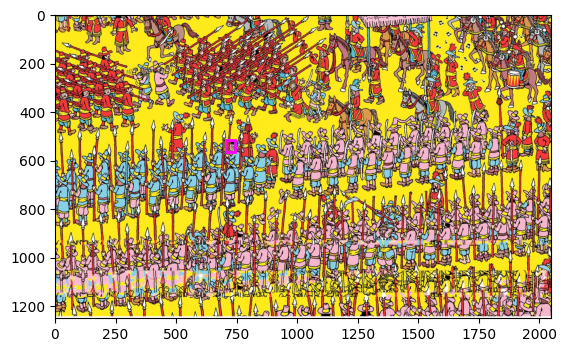

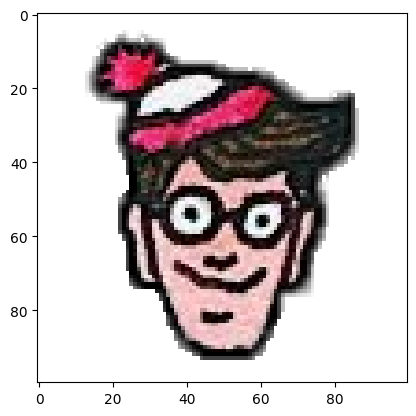

In [6]:
# implement your solution BELOW

fig, axes = plt.subplots()

axes.imshow(puzzle_images_dict['1.jpg']);

bbox_data = puzzle_im_waldo_bboxes_dict['1.jpg']
width = bbox_data['im width']
height = bbox_data['im height']
min_x = bbox_data['bbox left']
min_y = bbox_data['bbox top']
box_width = bbox_data['bbox width']
box_height = bbox_data['bbox height']

rect = matplotlib.patches.Rectangle((min_x, min_y), box_width, box_height, linewidth=2, edgecolor='magenta', facecolor='none')
axes.add_patch(rect)

plt.show()

plt.imshow(waldo_head_images_dict['waldo_head1.png'])
plt.show()



###**B**: Pozitív szintetikus példákat generáló függvény

Elsőként egy olyan függvényt kell definiálnunk, ami kivág egy megadott méretű képrészletet egy megadott teljes képrejtvény képből, majd egy megadott, kivágott Vili fejet tartalmazó, részben átlátszó képet véletlen pozícióban ráhelyez a háttérként használt képrészletre. Ez a függvény fogja majd a Vilit tartalmazó, pozitív példákat adni a hálónk tanításához. Mivel a különböző képrejtvényeken megjelenő Vili változatos méretű lehet, a szintetikus példáinkban is törekszünk erre: a kivágott fejet a képrészletre illesztés előtt átméretezzük.

Definiáld a `create_random_positive_sample` függvényt, mely sorban az alábbi paramétereket fogadja:
- `puzzle_image`: Egy teljes Vili képrejtvényt tartalmazó kép, NumPy tömbként, `(magasság, szélesség, csatornák_száma=3)` alakban, `np.uint8` adattípussal.
- `waldo_head_image`: Egy kivágott Vili-fejet tartalmazó kép, NumPy tömbként, `(magasság, szélesség, csatornák_száma=4)` alakban, `np.uint8` adattípussal. A kép negyedik csatornája az átlátszóságot kódolja, a notebook elején leírtak szerint.
- `waldo_head_scale`: Egy `float` típusú érték, ami megadja, hogy a Vili-fejet tartalmazó képet, a háttérre illesztés előtt milyen arányban kell átméretezni. Ha ez például 0.5, a `waldo_head_image` képet először mindkét tengely szerint fele akkorára kell átméretezni (lásd HF2 GYIK), majd ezt követően kell ráilleszteni a képre.
- `im_out_size_yx`: Egy kételemű, integer értékeket tartalmazó tuple, ami megadja, hogy a visszaadott képkivágás mekkora legyen (magasság, szélesség sorrenddel).

A függvény térjen vissza egy, a `puzzle_image` képből véletlenszerű helyről kivágott képpel, melyre kerüljön rá a `waldo_head_image` kép a `waldo_head_scale` érték szerint újraméretezve, véletlen pozícióba, úgy, hogy Vili feje lehetőleg ne lógjon le nagy mértékben a képről. A tömb alakja legyen `(im_out_size_yx[0], im_out_size_yx[1], 3)`, adattípusa `np.uint8`!

In [7]:
# implement your solution BELOW



def create_random_positive_sample(puzzle_image, waldo_head_image, waldo_head_scale, im_out_size_yx):

    start_pos_y = np.random.randint(0,puzzle_image.shape[0]-im_out_size_yx[0])
    start_pos_x = np.random.randint(0,puzzle_image.shape[1]-im_out_size_yx[1])
    final_image = puzzle_image[start_pos_y:start_pos_y+im_out_size_yx[0], start_pos_x:start_pos_x+im_out_size_yx[1],:].copy()

    scaled_waldo_head = skimage.transform.rescale(waldo_head_image,waldo_head_scale, channel_axis=2)
    scaled_waldo_head = np.round(scaled_waldo_head * 255).astype(np.uint8)

    scaled_waldo_head_rgb = scaled_waldo_head[:,:,:3]
    scaled_waldo_head_alpha = scaled_waldo_head[:,:,3]
    waldo_head_mask = scaled_waldo_head_alpha > 0

    waldo_head_start_y = np.random.randint(0,final_image.shape[0]-scaled_waldo_head.shape[0])
    waldo_head_start_x = np.random.randint(0,final_image.shape[1]-scaled_waldo_head.shape[1])
    waldo_head_place = final_image[waldo_head_start_y:waldo_head_start_y+scaled_waldo_head.shape[0], waldo_head_start_x:waldo_head_start_x+scaled_waldo_head.shape[1]]

    waldo_head_place[waldo_head_mask] = scaled_waldo_head_rgb[waldo_head_mask]

    return final_image

# implement your solution ABOVE

tester.test('B', create_random_positive_sample)


Tester: Task B solution seems OK


###**C**: Negatív szintetikus példákat generáló függvény

A Vilit tartalmazó, pozitív példák mellett szükségünk lesz Vilit nem tartalmazó negatív példákra is. Ebben a feladatban definiáljuk a negatív példákat előállító függvényt, mely képes úgy kivágni egy megadott méretű, véletlenszerűen választott képrészletet egy megadott teljes képrejtvény képből, hogy azon garantáltan ne legyen megtalálható Vili.

Definiáld a `create_random_negative_sample` függvényt, mely sorban az alábbi paramétereket fogadja:
- `puzzle_image`: Egy teljes Vili képrejtvényt tartalmazó kép, NumPy tömbként, `(magasság, szélesség, csatornák_száma=3)` alakban, `np.uint8` adattípussal.
- `waldo_bbox`: Egy négyelemű, integer értékeket tartalmazó tuple, ami megadja, hogy Vili hol helyezkedik el a `puzzle_image` képen, azaz Vili bounding box-át. Az értékek jelentése sorban: a bal oldal x koordinátája, a felső oldal y koordinátája, a téglalap szélessége, a téglalap magassága.
- `im_out_size_yx`: Egy kételemű, integer értékeket tartalmazó tuple, ami megadja, hogy a visszaadott képkivágás mekkora legyen (magasság, szélesség sorrenddel).

A függvény térjen vissza egy, Vili-t garantáltan nem tartalmazó, véletlenszerűen választott pozíciójú képkivágással egy NumPy tömb formájában! Azaz, a kivágott képrészletnek nem lehet közös pixele a Vilit tartalmazó bounding box-szal. A tömb alakja legyen `(im_out_size_yx[0], im_out_size_yx[1], 3)`, adattípusa `np.uint8`!

**Megjegyzés:** Egy lehetséges megközelítés az, ha véletlenszerű kivágást készítesz, majd ellenőrzöd, tartalmazza-e Vilit. Ha igen, eldobod és újat sorsolsz...

In [8]:
# implement your solution BELOW

def create_random_negative_sample(puzzle_image, waldo_bbox, im_out_size_yx):

  w_start_x, w_start_y, width, height = waldo_bbox

  w_end_x = w_start_x + width
  w_end_y = w_start_y + height

  while True:
    start_pos_y = np.random.randint(0,puzzle_image.shape[0]-im_out_size_yx[0])
    start_pos_x = np.random.randint(0,puzzle_image.shape[1]-im_out_size_yx[1])
    end_pos_y = start_pos_y + im_out_size_yx[0]
    end_pos_x = start_pos_x + im_out_size_yx[1]

    if start_pos_y < w_end_y and end_pos_y > w_start_y and start_pos_x < w_end_x and end_pos_x > w_start_x:
      continue
    else:
      final_image = puzzle_image[start_pos_y:start_pos_y+im_out_size_yx[0], start_pos_x:start_pos_x+im_out_size_yx[1],:].copy()
      return final_image



# implement your solution ABOVE

tester.test('C', create_random_negative_sample)


Tester: Task C solution seems OK


###**D**: A tanító-, validációs- és tesztképek elkülönítése

Ebben a feladatban elkülönítjük a betanításhoz, validációhoz és teszteléshez használt képrejtvényeket. Emellett, a kivágott Vili fejek közül is elkülönítünk néhányat validációs és tesztelési célokra, nem használjuk fel mindet a tanításhoz, hiszen ekkor nem tudnánk a tanítás végeztével, hogy korábban nem látott Vili fejkre hogyan reagál a háló.

- Készítsd el a `puzzle_image_names_train`, `puzzle_image_names_val`, `puzzle_image_names_test` listákat, melyek a képrejtvények fájlneveit (sztringek) tartalmazzák, úgy, ahogy azok a szótár kulcsai közt szerepeltek. Kerüljön 8 képrejtvény a tanítóhalmazba, 4 a validációs halmazba és 10 a teszthalmazba! A listák tartalma, természetesen, legyen diszjunkt.

- Hasonlóan, készítsd el a `waldo_head_image_names_train`, `waldo_head_image_names_val`, `waldo_head_image_names_test` sztring listákat is, melyek a kivágott Vili fejeket tartalmazó képek fájlneveit tartalmazzák, úgy, ahogy azok a szótár kulcsai közt szerepeltek. Kerüljön 8 Vili fej a tanítóhalmazba, 2-2 pedig a validációs- és a teszthalmazba! A listák tartalma, természetesen, legyen diszjunkt.


In [9]:
# implement your solution BELOW

im_keys_list = list(puzzle_images_dict.keys())

puzzle_image_names_train = im_keys_list[:8]
puzzle_image_names_val = im_keys_list[8:12]
puzzle_image_names_test = im_keys_list[12:22]

waldo_keys_list = list(waldo_head_images_dict.keys())

waldo_head_image_names_train = waldo_keys_list[:8]
waldo_head_image_names_val = waldo_keys_list[8:10]
waldo_head_image_names_test = waldo_keys_list[10:12]



# implement your solution ABOVE

tester.test('D', puzzle_image_names_train, puzzle_image_names_val, puzzle_image_names_test, \
                 waldo_head_image_names_train, waldo_head_image_names_val, waldo_head_image_names_test)


Tester: Task D solution seems OK


###**E**: Az adat-iterátorok létrehozása a neuronháló betanításához, adat-augmentáció

Az első házi feladathoz és zárthelyihez hasonlóan, ezúttal is iterátorokkal oldjuk meg a neuronhálónk betanítását. Ebben a részfeladatban **elő kell állítanod három iterátor objektumot** `dataloader_train`, `dataloader_val` és `dataloader_test` néven, melyek véletlenszerű szintetikus input képek kötegeit és az azokhoz tartozó bináris címkéket állítják elő. A képek elkészítéséhez, a B) és C) feladatokban implementált két függvényt kell segítségül hívnunk, a kettő közül minden generált kép esetén véletlenszerűen választva, 50-50% eséllyel. **Mindhárom iterátor a saját (tanító/validációs/teszt) halmazán dolgozzon**, azaz, amikor hívja a példageneráló függvényeket, az ezekből a halmazokból származó képrejtvényeket és Vili fej-képeket használja csak fel, azok közül véletlenszerűen választva! A pozitív példák generálásához javasolt a `waldo_head_scale` argumentumot a 0.3 és 0.8 értékek közti intervallumról  véletlenszerűen sorsolni. A negatív példák esetén a `waldo_bbox` paraméternél természetesen a megadott képrejtvényen valójában szereplő Vili bounding box-át kell megadni, hogy ki tudjuk őt szűrni a negatív képekről.

A képek esetén szükséges lesz a tengelyek sorrendjének átrendezése, mivel a csatornákat felsoroló tengely eddig hátul volt (_channel-last_ formátum: NHWC), de a PyTorch erre a tengelyre közvetlenül a kötegméret tengely után számít (_channel-first_ formátum: NCHW). Ebből kifolyólag, a visszaadott tenzorok alakja `(batch_size, 3, 128, 128)` és `(batch_size, 1)` lesz. Előbbi a színes képeket tartalmazza változatlan felbontással, utóbbi a képekhez tartozó bináris klasszifikációs címkéket. `batch_size` a mintaelemek számát adja meg, melyeket egyszerre, egy kötegben fog megkapni a neuronhálónk - ennek értéke lehet például 32.

Hangsúlyozandó, hogy az iterátorok a fent említett NumPy tömbökből (`np.ndarray`) nyert mintaelem-kötegeket már `torch.tensor` típusú objektumokként adják vissza (pontosabban, kételemű tuple-öket adnak vissza, melyekben `torch.tensor` objektumok lesznek). A PyTorch-al definiált neuronhálók betanításához már mindenképp PyTorch tenzorok szükségesek: az input tenzor és a bináris címkéket tartalmazó tenzor **adattípusa** is 4 bájtos lebegőpontos típus (`torch.float32`) kell, hogy legyen.

A neuronhálónk egy előtanított mély konvolúciós hálón alapul majd, ezért a képeinket olyan formátumra kell hoznunk, amilyet a háló a betanításakor látott. Az eredetileg [0, 255] intervallumbeli értékeket tartalmazó képeinket először a [0, 1] intervallumra kell leskáláznunk, majd színcsatornánként megadott átlag (`MOBILENET_MEANS`) és szórás (`MOBILENET_STDS`) értékekkel kell sztenderdizálnunk. Az iterátor által visszaadott képek színcsatornánként függetlenül vett átlaga tehát 0 körül, szórása pedig 1 körül lesz a helyes sztenderdizáció után.

Az iterátorok implementációja többféleképpen megoldható. Például, egyedi generátorral/iterátorral, vagy a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai felhasználásával és esetleges származtatásával. Mivel ebben az esetben nincsen fix adatbázisunk, tetszőleges számban tudunk véletlen képkivágásokat generálni, ezért **az iterátorok** (vagy a `Dataset`) **hosszát manuálisan kell megadnunk** - ez fogja megadni egy epoch hosszát is a betanításkor. Nem érdemes ezt a számot néhány száz elemnél nagyobbra állítani.

**Adat-augmentáció:** Sajnos az adatbázisunk rendkívül kis méretű, így erre várhatóan könnyen túltanulna a hálónk, új tanítóadatot beszerezni pedig nincs lehetőségünk. Ezért, az adat-augmentálás technikájához kell fordulnunk. Az adat-augmentációt a B) és C) feladatban definiált függvények által generált képeken alkalmazzuk.

Alkalmazz véletlenszerű adat-augmentációt a **tanító** iterátorban, hogy csökkentsd a túltanulás valószínűségét! Az adat-augmentációs módszerek közt legyen kis méretékű transzláció (eltolás), forgatás, skálázás, zaj, illetve a kép színeinek torzítása! A validációs- és teszt-iterátorok ne alkalmazzank adat-augmentációt, hiszen ezeket kiértékeléshez fogjuk használni! Az adat-augmentációhoz javasolt (de nem kötelező) a `torchvision.transforms` modul eszközeit használni. Ennek segítségével a sztenderdizáció is megoldható. A használatára láthatsz példákat a fent említett notebook-ban / videóban és a PyTorch dokumentációjában is.



In [10]:

import random
MOBILENET_MEANS = [0.485, 0.456, 0.406]
MOBILENET_STDS = [0.229, 0.224, 0.225]   # MobileNet v2 stats used for image normalization

# implement your solution BELOW

class ImageClassificationDataset(Dataset):
    def __init__(self, puzzle_image_names, waldo_head_names,im_out_size, epoch_length, transform):
        self.puzzle_image_names = puzzle_image_names
        self.waldo_head_names = waldo_head_names
        self.im_out_size = im_out_size
        self.length = epoch_length
        self.transform = transform


    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        pos_or_neg = np.random.randint(0,2)

        puzzle_name = random.choice(self.puzzle_image_names)
        waldo_head_name = random.choice(self.waldo_head_names)

        if pos_or_neg == 1 :
          waldo_head_scale = np.random.uniform(0.3,0.8)
          final_image = create_random_positive_sample(puzzle_images_dict[puzzle_name], waldo_head_images_dict[waldo_head_name],waldo_head_scale, self.im_out_size)
          label = 1.0
        else:
          waldo_bbox = puzzle_im_waldo_bboxes_dict[puzzle_name]
          w_start_x = waldo_bbox['bbox left']
          w_start_y = waldo_bbox['bbox top']
          width = waldo_bbox['bbox width']
          height = waldo_bbox['bbox height']
          waldo_bbox_tuple = w_start_x,w_start_y,width,height
          final_image = create_random_negative_sample(puzzle_images_dict[puzzle_name], waldo_bbox_tuple, self.im_out_size)
          label = 0.0


        final_image=self.transform(final_image)
        label = torch.tensor([label], dtype=torch.float32)

        return final_image, label

train_transform = transforms.v2.Compose([
    transforms.v2.ToImage(),
    transforms.v2.ToDtype(torch.float32, scale=True),
    transforms.v2.RandomHorizontalFlip(),
    transforms.v2.RandomErasing(p=0.3),
    transforms.v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.v2.RandomAffine(degrees=15., translate=(0.2, 0.2), scale=(0.8, 1.2)),
    torchvision.transforms.Normalize(MOBILENET_MEANS, MOBILENET_STDS)
])

eval_transform = transforms.v2.Compose([
    transforms.v2.ToImage(),
    transforms.v2.ToDtype(torch.float32, scale=True),
    torchvision.transforms.Normalize(MOBILENET_MEANS, MOBILENET_STDS)
])


train_dataset = ImageClassificationDataset(puzzle_image_names_train, waldo_head_image_names_train, (128,128), 200, transform=train_transform)
val_dataset = ImageClassificationDataset(puzzle_image_names_val, waldo_head_image_names_val, (128,128), 200,transform=eval_transform)
test_dataset = ImageClassificationDataset(puzzle_image_names_test, waldo_head_image_names_test, (128,128), 200, transform=eval_transform)

dataloader_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_test = DataLoader(test_dataset, batch_size=32, shuffle=False)


# implement your solution ABOVE

tester.test('E', dataloader_train, dataloader_val, dataloader_test)


Tester: Task E solution seems OK


###**F**: Néhány augmentált kép kirajzolása az adat-iterátorból

Azért, hogy lássuk, a hálónk megfelelő inputot és címkéket fog kapni, mintavételezünk pár képet és címkét az E) feladatban elkészített iterátorokból és kirajzoljuk ezeket.
- Mintavételezz néhány képet és a hozzájuk tartozó címkéket a `dataloader_train` és `dataloader_val` iterátorokból, majd rajzold ki ezeket a képeket és írd föléjük a hozzájuk tartozó címkét (például "1")! Mivel az iterátorok a képeket normalizálják és megváltoztatják a tengelysorrendet is, a helyes kirajzoláshoz ezeket a transzformációkat vissza kell csinálni a kirajzolás előtt.

_**Megjegyzés:** Ha korábban nem tetted volna, itt tudod vizuálisan is ellenőrizni, hogy a B) és C) feladatok függvényei jól működnek-e. Továbbá, itt látod azt is, hogy az adat-augmentáció helyes-e, csak a tanító-iterátoron van-e jelen az, és hogy helyes kategóriacímkék kerülnek-e a képekhez._

Batch shapes: (32, 128, 128, 3) (32, 1)
Batch xs min, max: 0.0 1.0


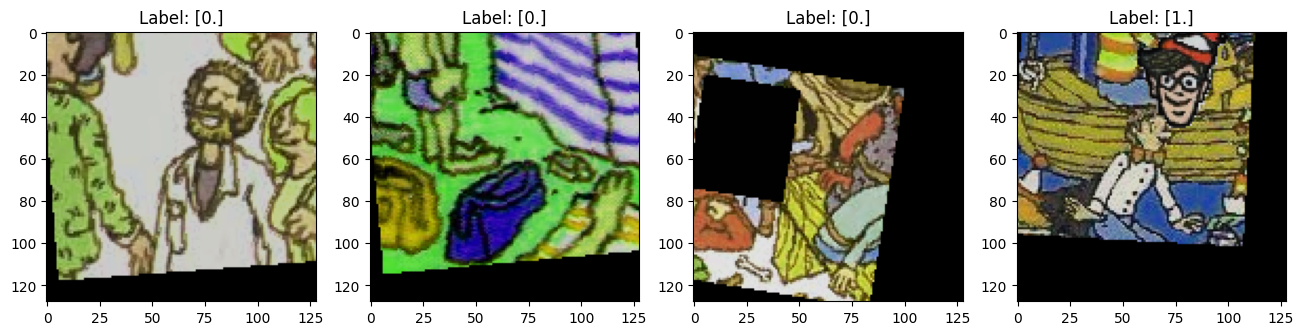

Batch shapes: (32, 128, 128, 3) (32, 1)
Batch xs min, max: 0.0 1.0


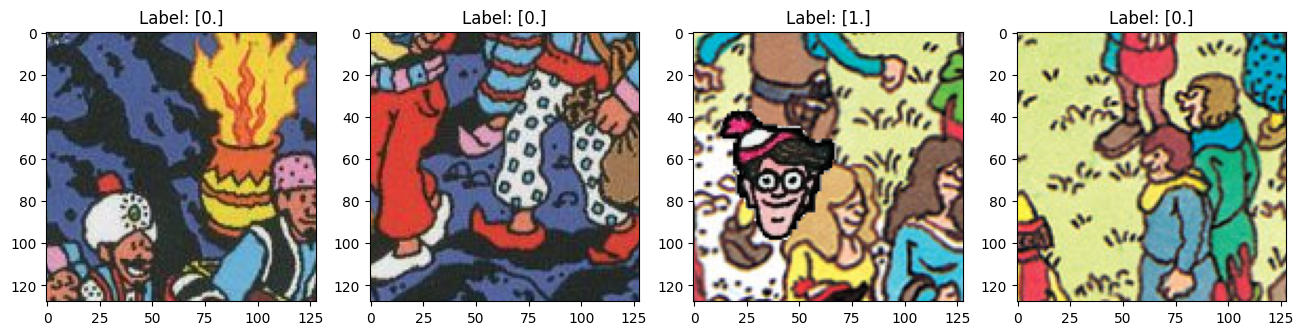

In [11]:
# implement your solution BELOW
MOBILENET_MEANS = [0.485, 0.456, 0.406]
MOBILENET_STDS = [0.229, 0.224, 0.225]


for sample_xs, sample_ys in dataloader_train:
  sample_xs = sample_xs.permute(0, 2, 3, 1)
  sample_xs = sample_xs.numpy()
  sample_xs = (sample_xs * MOBILENET_STDS) + MOBILENET_MEANS
  sample_xs = np.clip(sample_xs, 0.0, 1.0)
  sample_ys = sample_ys.numpy()

  break


fig, axes = plt.subplots(1, 4, figsize=(16, 4))
print("Batch shapes:", sample_xs.shape, sample_ys.shape)
print("Batch xs min, max:", np.amin(sample_xs), np.amax(sample_xs))
for i in range(4):
  axes[i].imshow(sample_xs[i,:,:,:])
  axes[i].set_title("Label: " + str(sample_ys[i]))

plt.show()


for sample_xs, sample_ys in dataloader_val:
  sample_xs = sample_xs.permute(0, 2, 3, 1)
  sample_xs = sample_xs.numpy()
  sample_xs = (sample_xs * MOBILENET_STDS) + MOBILENET_MEANS
  sample_xs = np.clip(sample_xs, 0.0, 1.0)
  sample_ys = sample_ys.numpy()
  break

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
print("Batch shapes:", sample_xs.shape, sample_ys.shape)
print("Batch xs min, max:", np.amin(sample_xs), np.amax(sample_xs))
for i in range(4):
  axes[i].imshow(sample_xs[i,:,:,:])
  axes[i].set_title("Label: " + str(sample_ys[i]))

plt.show()





###**G**: A konvolúciós háló definiálása bináris klasszifikációhoz

A konvolúciós hálónk alapját egy, az ImageNet adatbázison előtanított MobileNet v2 neuronháló adja. Ezt alapul véve (és a tanult súlyainak nagyrészét felhasználva) készítjük el a célfeladat megoldására alkalmas konvolúciós hálónkat, amit finomhangolunk az adatbázisunkon.

**Definiáld a bináris klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja!

Töltsd be a MobileNet v2 neuronhálót előtanított súlyokkal, majd ennek egyik konvolúciós rétegéhez (például: `features[17].conv[3]`) fűzz hozzá egy kisméretű neuronhálót, melynek architektúrája alkalmas a feladatunk megoldására! A háló végén található aktivációs függvényre mindenképp figyelj oda!

Egy javaslat a hozzáfűzendő rétegekre (nem kötelező):
- Egy konvolúciós réteg nem túl nagyszámú (pl. 32) filterrel.
- Két teljesen összekötött réteg, ahol az utolsó neuronjainak számát a feladat határozza meg.
- A rétegek közt aktivációs függvények vannak (pl. ReLU).

**Példányosítsd az új osztályt** és add értékül a `finetuned_model` nevű változónak a példányt!

_**Megjegyzés:** A MobileNet háló súlyainak befagyasztása itt nem biztos, hogy jó ötlet, hiszen a Vili képrejtvények stílusa eltérhet attól, amin a háló eredetileg tanítva lett._

In [12]:
# implement your solution BELOW


class MobileNet2_FineTunedForBinaryClassClassification(nn.Module):

    def __init__(self):
        super().__init__()
        self.mobile_net = torch.hub.load('pytorch/vision', 'mobilenet_v2', weights='MobileNet_V2_Weights.IMAGENET1K_V1')
        self.mobile_net_output = None
        self.mobile_net.features[17].conv[3].register_forward_hook(self._hook)


        self.extra_conv = nn.Conv2d(320, 40, kernel_size = (3,3), padding='same')  # out: (bs, 320, 4, 4) if input size is (128, 128)
        self.extra_fc = nn.Sequential(
            nn.ReLU(),
            nn.Linear(40*4*4, 20),
            nn.ReLU(),
            nn.Linear(20, 1),
            nn.Sigmoid()
        )

    def _hook(self, module, input, output):
        self.mobile_net_output = output   # (batch_size, 320, 4, 4)

    def forward(self, x):
        _ = self.mobile_net(x)
        out = self.extra_conv(self.mobile_net_output)
        out = out.reshape(out.size(0), -1)
        out = self.extra_fc(out)
        return out


finetuned_model = MobileNet2_FineTunedForBinaryClassClassification()


# implement your solution ABOVE

tester.test('G', finetuned_model)

Downloading: "https://github.com/pytorch/vision/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 171MB/s]


Tester: Task G solution seems OK


###**H**: A háló betanítása bináris klasszifikációs feladatra

**Tanítsd be az** `finetuned_model` **neuronhálót** a tanítópéldákon a `dataloader_train` iterátor segítségével és alkalmazd a `dataloader_val` iterátort a validációhoz!

Alkalmazd a bináris klasszifikációkor szokásosan használt **binary cross-entropy költséget**! **Mérd le minden epoch-ban a tanító- és a validációs példákon a költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonon a jelmagyarázat meglétére és a görbék könnyű elkülöníthetőségére figyelj ezúttal is! **Számold ki az _accuracy_ (pontosság) metrikát minden epoch-ban a tanító- és a validációs példákon** és jelöld ezek alakulását is a grafikonon!

A tanítást az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza a `finetuned_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

A betanítást követően **számold ki a költséget és az _accuracy_ metrikát a teszt-iterátorból mintavételezett példahalmazon is** és add értékül a kapott számot a `test_bce` és `test_acc` változóknak!

_**Megjegyzés:** Mivel ezúttal nincsenek fix tanító-, validációs- és teszthalmazok a generált képrészleteket tekintve, az iterátorok hosszával, vagy manuálisan lehet szabályozni, hogy hány példán mérjük le a költségeket/metrikákat._

Epoch #0, tr loss: 0.22277066111564636, val loss: 0.04482683539390564, tr acc: 0.8928571343421936, val acc: 0.9821428656578064
    Early stopping: Best model updated.
Epoch #1, tr loss: 0.1279323250055313, val loss: 0.03993900492787361, tr acc: 0.9598214030265808, val acc: 0.9866071343421936
    Early stopping: Best model updated.
Epoch #2, tr loss: 0.10795186460018158, val loss: 0.01999284140765667, tr acc: 0.96875, val acc: 0.9955357313156128
    Early stopping: Best model updated.
Epoch #3, tr loss: 0.15277183055877686, val loss: 0.0272243469953537, tr acc: 0.9508928656578064, val acc: 0.9910714030265808
Epoch #4, tr loss: 0.2052234411239624, val loss: 0.07744164764881134, tr acc: 0.9375, val acc: 0.9821428656578064
Epoch #5, tr loss: 0.20139513909816742, val loss: 0.04700735956430435, tr acc: 0.9419642686843872, val acc: 1.0
Epoch #6, tr loss: 0.15453019738197327, val loss: 0.01642409898340702, tr acc: 0.9508928656578064, val acc: 0.9910714030265808
    Early stopping: Best model u

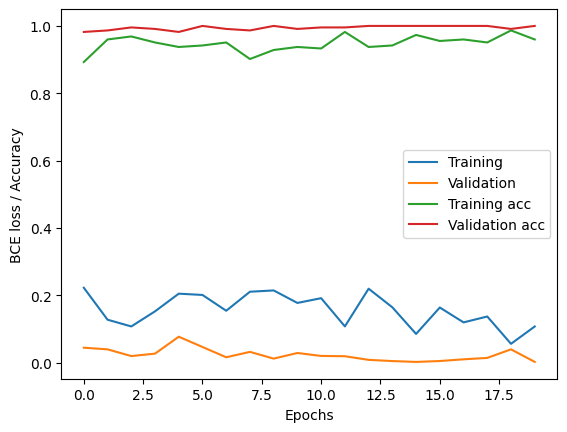


Tester: Task H solution seems OK


In [26]:
# implement your solution BELOW

@torch.no_grad()
def acc_fn(y_hat, y_true):
    y_hat_am = (y_hat >= 0.5).float()
    return torch.count_nonzero(y_hat_am == y_true) / y_hat.shape[0]

loss_fn = nn.BCELoss()

n_epochs = 20
learning_rate = 0.001
optimizer = torch.optim.Adam(finetuned_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []
best_finetuned_model = None
best_val_loss = float('inf')
early_stopping_patience = 5
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_epochs):
  finetuned_model.train()
  train_epoch_losses = []
  train_epoch_accs = []

  for x, y in dataloader_train:

    optimizer.zero_grad()
    y_hat = finetuned_model(x)
    loss = loss_fn(y_hat, y)
    acc = acc_fn(y_hat, y)
    train_epoch_losses.append(loss.detach())
    train_epoch_accs.append(acc)
    loss.backward()
    optimizer.step()


  train_epoch_losses = torch.tensor(train_epoch_losses)
  train_epoch_accs = torch.tensor(train_epoch_accs)
  avg_tr_epoch_loss = train_epoch_losses.mean()
  avg_tr_epoch_acc = train_epoch_accs.mean()
  train_losses.append(avg_tr_epoch_loss)
  train_accuracy.append(avg_tr_epoch_acc)

  finetuned_model.eval()
  val_epoch_losses = []
  val_epoch_accs = []

  for x, y in dataloader_val:

    with torch.no_grad():
      y_hat = finetuned_model(x)

    loss = loss_fn(y_hat, y)
    acc = acc_fn(y_hat, y)
    val_epoch_losses.append(loss)
    val_epoch_accs.append(acc)

  val_epoch_losses = torch.tensor(val_epoch_losses)
  val_epoch_accs = torch.tensor(val_epoch_accs)
  avg_val_epoch_loss = val_epoch_losses.mean()
  avg_val_epoch_acc = val_epoch_accs.mean()
  val_losses.append(avg_val_epoch_loss)
  val_accuracy.append(avg_val_epoch_acc)

  print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")


  if avg_val_epoch_loss < best_val_loss:
    best_val_loss = avg_val_epoch_loss
    best_finetuned_model = copy.deepcopy(finetuned_model)
    last_early_stopping_update_ep_idx = epoch_idx
    print("    Early stopping: Best model updated.")


  if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
    print("Training is terminated by early stopping.")
    break


print("Best model weights are restored.")
finetuned_model = best_finetuned_model


test_pred_y_cat = []
test_y_cat = []

with torch.no_grad():
    _, (test_x, test_y) = next(enumerate(dataloader_test))
    test_x = test_x
    test_pred_y_cat_batch_npy = (finetuned_model(test_x) >= 0.5).int().flatten().numpy()
    test_pred_y_cat.append(test_pred_y_cat_batch_npy)
    test_y_cat.append(test_y.numpy())
test_pred_y_cat = np.concatenate(test_pred_y_cat, axis=0)
test_y_cat = np.concatenate(test_y_cat, axis=0)


with torch.no_grad():
  test_pred_ys = []
  test_ys = []
  for x, y in dataloader_test:
    y_hat = finetuned_model(x)
    test_pred_ys.append(y_hat)
    test_ys.append(y)

  test_pred_ys = torch.cat(test_pred_ys, dim=0)
  test_ys = torch.cat(test_ys, dim=0)
  test_bce = loss_fn(test_pred_ys, test_ys)
  test_acc = acc_fn(test_pred_ys, test_ys)
  print(f"Test metrics - BCE: {test_bce}, acc: {test_acc}")

for sample_idx in range(10):
  print(f"Test sample #{sample_idx}, pred vs true label: {test_pred_y_cat[sample_idx]} vs {test_y_cat[sample_idx]}")

plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()



# implement your solution ABOVE

tester.test('H', test_bce, test_acc)

###**I**: Az adat-iterátorok létrehozása a neuronháló kiértékeléséhez egy-egy teljes méretű Vili képrejtvényen

Vilit úgy próbáljuk meg megkeresni a nagy képeken, hogy **felosztjuk a képeket** akkora **ablakokra** (128 x 128), amekkorán a neuronhálót betanítottuk a Vilit tartalmazó és nem tartalmazó képrészletek klasszifikálására, **majd a betanult neuronhálóval klasszifkáljuk a felosztott képet**, ablakonként haladva.

A nagy képek ilyen módon történő **felosztására és bejárására egy új adat-iterátort definiálunk**, mely sorfolytonosan bejár egy megadott Vili képrejtvényt és szükséges méretű képrészleteket vág ki, majd ad vissza sorban. A képrészletek mellett azok bináris címkéjét is visszaadja az iterátor, aszerint, hogy az éppen soron következő képrészletnek van-e közös pixele a képrejtvényen található Vili bounding box-ával.

Készítsd el a `dataloader_puzzleimg_eval` iterátort, mely az egyik, teszthalmazban található Vili képrejtényen végigmegy és sorfolytonosan felsorolja a kép 128 x 128 pixeles felbontású szeleteit!  A szeletek lehetnek egy rács cellái, de kissé jobb eredmény érhető el, ha a szomszédos rács-cellák szélei átfedik egymást kissé - így Vili feje valamelyik kivágott képrészletben megtalálható lesz egészben. A képrészletekkel együtt az iterátor adja vissza azok bináris címkéit is, azaz 1 értéket, ha a képrészletnek van metszete Vili bounding boxával és 0 értéket, ha nincs! Az iterátor pontosan egy teljes képrejtvényen menjen végig!

**Az iterátor által visszaadott tenzorok alakja és adattípusa ugyanaz lesz, mint a tanításra használt iterátorok esetében**, a tengelysorrend-cserére és a normalizációra itt is figyelni kell. Az iterátorok implementációja többféleképpen megoldható. Például, egyedi generátorral/iterátorral, vagy a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai felhasználásával és esetleges származtatásával. Adat-augmentációt ezúttal nem alkalmazunk, hiszen már csak kiértékeljük a betanított hálónkat.


In [14]:
# implement your solution BELOW


class WaldoWindowDataset(Dataset):
  def __init__(self,puzzle_image, waldo_bbox):
    self.puzzle_image = puzzle_image
    self.waldo_bbox = waldo_bbox
    self.coordinates = []

    im_height, im_width = puzzle_image.shape[:2]
    for y in range(0,im_height-128+1,64):
      for x in range(0,im_width-128+1,64):
        self.coordinates.append((x,y))

  def __len__(self):
    return len(self.coordinates)

  def __getitem__(self, idx):
    w_start_x = self.waldo_bbox['bbox left']
    w_start_y = self.waldo_bbox['bbox top']
    width = self.waldo_bbox['bbox width']
    height = self.waldo_bbox['bbox height']

    w_end_x = w_start_x + width
    w_end_y = w_start_y + height

    start_pos_x, start_pos_y = self.coordinates[idx]
    end_pos_x = start_pos_x + 128
    end_pos_y = start_pos_y + 128

    if start_pos_y < w_end_y and end_pos_y > w_start_y and start_pos_x < w_end_x and end_pos_x > w_start_x:
      label = 1.0
    else:
      label = 0.0

    image_piece = self.puzzle_image[start_pos_y:end_pos_y, start_pos_x:end_pos_x,:].copy()
    image_piece = custom_transform(image_piece)
    label = torch.tensor([label], dtype=torch.float32)
    return image_piece, label


custom_transform = transforms.v2.Compose([
    transforms.v2.ToImage(),
    transforms.v2.ToDtype(torch.float32, scale=True),
    torchvision.transforms.Normalize(MOBILENET_MEANS, MOBILENET_STDS)
])


window_dataset = WaldoWindowDataset(puzzle_images_dict['3.jpg'], puzzle_im_waldo_bboxes_dict['3.jpg'])
dataloader_puzzleimg_eval = DataLoader(window_dataset, batch_size = 32, shuffle=False)

# implement your solution ABOVE

tester.test('I', dataloader_puzzleimg_eval)


Tester: Task I solution seems OK


###**J**: A háló kiértékelése a nagy méretű Vili képek képrészletein, Vili detektálása

Alkalmazd a fenti iterátort egy szabadon választott Vili képrejtvényen Vili megkeresésére! Állítsd elő az alábbi négy grafikont:
- **Rajzold ki a választott képrejtvényt Vili igazi bounding box-ával**!
- **Nyerd ki az iterátorból az összes képrészlet igazi címkéjét, majd formáld át úgy a tömbbe rendezett címkéket egy mátrixszá,** hogy ha kirajzolod a mátrixot, a képpel az összevethető és látszik, hogy a képen hol található meg Vili! Rajzold is ki ezt a mátrixot!
- **Nyerd ki az iterátorból az összes képrészletet, becsüld a címkéjüket a betanított hálóval, majd formáld át úgy a tömbbe rendezett becsült címkéket egy mátrixszá,** hogy ha kirajzolod a mátrixot, a képpel az összevethető és látszik, hogy hol milyen valószínűségeket sejt Vili jelenlétére a háló! Rajzold is ki ezt a mátrixot!
- **Rajzold ki az előző mátrixnak egy olyan változatát, ahol csak a maximális elem értékét tartod meg,** az összes többi elem értékét nullára állítod!

Példát a kirajzolandó grafikonra a Canvas-ban, a "HF2 GYIK" fórumon találsz.

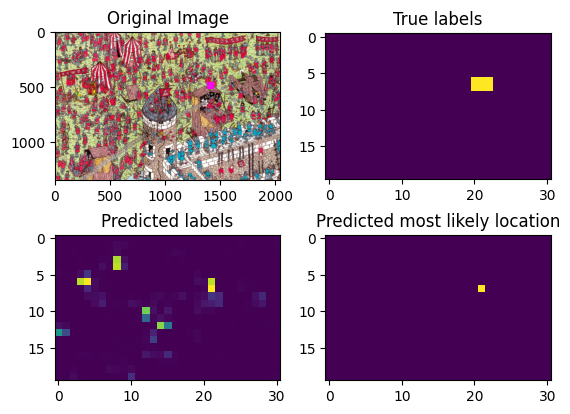

In [25]:
# implement your solution BELOW


fig, axes = plt.subplots(2,2)

axes[0,0].imshow(puzzle_images_dict['3.jpg']);

image = puzzle_images_dict['3.jpg']

bbox_data = puzzle_im_waldo_bboxes_dict['3.jpg']
width = bbox_data['im width']
height = bbox_data['im height']
min_x = bbox_data['bbox left']
min_y = bbox_data['bbox top']
box_width = bbox_data['bbox width']
box_height = bbox_data['bbox height']

rect = matplotlib.patches.Rectangle((min_x, min_y), box_width, box_height, linewidth=2, edgecolor='magenta', facecolor='none')
axes[0,0].add_patch(rect)
axes[0,0].set_title("Original Image")



true_labels_list = []
predictions_list = []

finetuned_model.eval() # FIXED: Evaluation mode
with torch.no_grad():
  for sample_x, sample_y in dataloader_puzzleimg_eval:
    true_label = sample_y
    true_labels_list.extend(true_label.flatten().numpy())
    prediction = finetuned_model(sample_x)
    predictions_list.extend(prediction.flatten().numpy())

true_labels_list_np = np.array(true_labels_list)
predictions_list_np = np.array(predictions_list)

im_height, im_width = image.shape[:2]
rows = ((im_height - 128)//64)+1
cols = ((im_width - 128)//64)+1

true_labels_mtx = true_labels_list_np.reshape(rows,cols)
axes[0,1].imshow(true_labels_mtx)
axes[0,1].set_title("True labels")

predictions_mtx = predictions_list_np.reshape(rows,cols)
axes[1,0].imshow(predictions_mtx)
axes[1,0].set_title("Predicted labels")


max_pred_mtx = np.zeros_like(predictions_mtx)
pred_mask = (predictions_mtx == np.max(predictions_mtx))
max_pred_mtx[pred_mask] =  1

axes[1,1].imshow(max_pred_mtx)
axes[1,1].set_title("Predicted most likely location")


plt.show()
